# Inflation

## 04.01. Painel Integrado da Dinâmica Inflacionária

### De um número para uma leitura multidimensional da inflação

O projeto **Inflation** começou com uma pergunta simples:

> Quanto foi a inflação?

A primeira etapa foi compreender o IPCA e sua estrutura:

```text
IPCA
 |
 +-- grupos
 |
 +-- subgrupos
 |
 +-- itens
 |
 +-- subitens
```

Depois, avançamos para a decomposição e validação dessa hierarquia.

Agora entramos em uma nova etapa:

> **Como a inflação está se formando e evoluindo?**

O objetivo deste notebook é apresentar um painel que combina diferentes
dimensões do processo inflacionário em uma única leitura.

```text
Momentum
    ↓
velocidade

Difusão
    ↓
abrangência

Inflação aparada
    ↓
pressão subjacente experimental

Choques setoriais
    ↓
localização das pressões
```

Este notebook tem propósito analítico e de comunicação.

O resultado será utilizado como base para um relatório em PDF sobre
a evolução do projeto.

---

# 1. Por que o IPCA sozinho não conta toda a história?

O IPCA mensal resume milhares de movimentos de preços em um único número.

Porém, dois meses com o mesmo IPCA podem possuir estruturas bastante
diferentes.

Por exemplo:

```text
mesmo IPCA
   |
   +-- muitos preços subindo pouco
   |
   +-- poucos preços subindo muito
   |
   +-- grandes altas e quedas se compensando
   |
   +-- pressão persistente
   |
   +-- choque concentrado em poucos setores
```

Por isso, além do índice cheio, o painel observa:

1. velocidade;
2. abrangência;
3. inflação subjacente experimental;
4. origem setorial das pressões.

---

# 2. Os quatro indicadores do painel

## 2.1 Momentum

Utilizamos a média móvel de três meses:

$$
M_t^{(3)}
=
\frac{
\pi_t+\pi_{t-1}+\pi_{t-2}
}{
3
}
$$

A média móvel reduz parte da volatilidade de um único mês e fornece
uma referência para observar o comportamento recente do IPCA.

No painel também destacamos visualmente o último episódio contínuo
de aumento do IPCA mensal.

A pergunta é:

> **A inflação recente está ganhando ou perdendo força?**

## 2.2 Difusão

A difusão mede a proporção de subitens cuja variação mensal foi positiva.

$$
D_t
=
\frac{
\sum_{i=1}^{N_t}
\mathbf{1}(\pi_{i,t}>0)
}{
N_t
}
$$

Assim:

```text
IPCA
   ↓
intensidade agregada

Difusão
   ↓
abrangência das altas
```

Uma difusão de $70\%$, por exemplo, significa que 7 em cada 10
componentes observados apresentaram aumento de preços.

A pergunta é:

> **A inflação está se espalhando entre os componentes?**

## 2.3 Tendência da difusão

Para a janela recente ajustamos uma regressão linear:

$$
\widehat{D}_t
=
\beta_0+\beta_1t
$$

O coeficiente $\beta_1$ é o **slope**, ou inclinação da reta.

Portanto:

$$
\beta_1>0
\Rightarrow
\text{tendência crescente}
$$

$$
\beta_1<0
\Rightarrow
\text{tendência decrescente}
$$

O slope descreve a direção da série dentro da janela observada.

**Não representa previsão.**

## 2.4 Inflação aparada experimental

Alguns componentes podem apresentar movimentos extremos e exercer forte
influência sobre a inflação cheia.

Como exercício analítico, construímos uma média aparada:

```text
ordenar subitens por variação
             ↓
remover extremos inferiores
             ↓
remover extremos superiores
             ↓
média ponderada do conjunto restante
```

Neste painel utilizamos uma apara experimental de $20\%$ em cada cauda.

A medida procura responder:

> **A pressão inflacionária permanece quando reduzimos a influência
> dos movimentos extremos?**

Esta medida é experimental e não representa um núcleo oficial de inflação.

## 2.5 Choques setoriais

Para cada grupo $g$, utilizamos a contribuição:

$$
C_{g,t}
=
\pi_{g,t}
\frac{w_{g,t}}{100}
$$

O heatmap permite identificar:

- contribuições positivas;
- contribuições negativas;
- persistência das pressões;
- alternância entre setores;
- mudanças na composição da inflação.

A pergunta é:

> **Onde estão as principais pressões sobre o IPCA?**

---

# 3. Preparação

Esta seção reproduz somente os cálculos necessários para gerar o painel.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name in {
    "notebooks",
    "reports",
}:
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

print(
    "Project root:",
    PROJECT_ROOT,
)

Project root: /home/moacir/projects/ml/analytics/inflation


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression

from src.database.connection import engine

pd.set_option(
    "display.float_format",
    "{:.4f}".format,
)

---

# 4. Dados

In [3]:
ipca = pd.read_sql(
    """
    SELECT
        date,
        indice,
        acumulado12m
    FROM bcb.ipca_geral
    ORDER BY date;
    """,
    engine,
)

ipca["date"] = pd.to_datetime(
    ipca["date"]
)

ipca = (
    ipca
    .sort_values("date")
    .reset_index(drop=True)
)

In [4]:
subitens = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_subitens
    ORDER BY date, categoria;
    """,
    engine,
)

subitens["date"] = pd.to_datetime(
    subitens["date"]
)

subitens["categoria"] = (
    subitens["categoria"]
    .astype(str)
)

subitens["contribuicao"] = (
    subitens["indice"]
    * subitens["peso"]
    / 100
)

In [5]:
grupos = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_grupos
    ORDER BY date, categoria;
    """,
    engine,
)

grupos["date"] = pd.to_datetime(
    grupos["date"]
)

grupos["contribuicao"] = (
    grupos["indice"]
    * grupos["peso"]
    / 100
)

---

# 5. Construção dos indicadores

## 5.1 Momentum

In [6]:
ipca["momentum_3m"] = (
    ipca["indice"]
    .rolling(3)
    .mean()
)

df_ipca = (
    ipca[
        [
            "date",
            "indice",
            "momentum_3m",
        ]
    ]
    .rename(
        columns={
            "indice": "ipca",
        }
    )
    .dropna()
    .tail(13)
    .reset_index(drop=True)
)

### Último ciclo de aumento do IPCA mensal

Para o destaque visual identificamos o episódio contínuo mais recente
em que:

$$
\pi_t>\pi_{t-1}
$$

A faixa começa no mês anterior à primeira alta, representando o ponto
a partir do qual se inicia o movimento.

In [7]:
df_ipca["acelera"] = (
    df_ipca["ipca"]
    > df_ipca["ipca"].shift(1)
)

acelera = (
    df_ipca["acelera"]
    .fillna(False)
)

inicio = None
fim = None

posicoes = np.flatnonzero(
    acelera.to_numpy()
)

if len(posicoes) > 0:

    fim_pos = posicoes[-1]
    inicio_pos = fim_pos

    while (
        inicio_pos > 0
        and acelera.iloc[
            inicio_pos - 1
        ]
    ):
        inicio_pos -= 1

    inicio_plot = max(
        inicio_pos - 1,
        0,
    )

    inicio = (
        df_ipca["date"]
        .iloc[inicio_plot]
    )

    fim = (
        df_ipca["date"]
        .iloc[fim_pos]
    )

## 5.2 Difusão

In [8]:
df_difusao = (
    subitens
    .assign(
        alta=(
            subitens["indice"] > 0
        )
    )
    .groupby("date")["alta"]
    .mean()
    .mul(100)
    .rename("difusao")
    .reset_index()
    .tail(13)
    .reset_index(drop=True)
)

## 5.3 Inflação aparada experimental

In [9]:
def media_aparada(
    grupo,
    proporcao=0.20,
):

    dados = (
        grupo
        .sort_values("indice")
        .copy()
    )

    n = len(dados)

    corte = int(
        n * proporcao
    )

    if (
        n == 0
        or 2 * corte >= n
    ):
        return np.nan

    miolo = dados.iloc[
        corte:
        n - corte
    ]

    if miolo["peso"].sum() == 0:
        return np.nan

    return np.average(
        miolo["indice"],
        weights=miolo["peso"],
    )

In [10]:
df_trim = (
    subitens
    .groupby("date")
    .apply(
        media_aparada,
        proporcao=0.20,
        include_groups=False,
    )
    .rename(
        "nucleo_aparado"
    )
    .reset_index()
    .dropna()
    .tail(13)
    .reset_index(drop=True)
)

## 5.4 Choques setoriais

In [11]:
df_heat = (
    grupos
    .groupby(
        [
            "date",
            "categoria_nome",
        ]
    )["contribuicao"]
    .sum()
    .reset_index()
    .pivot(
        index="date",
        columns="categoria_nome",
        values="contribuicao",
    )
    .sort_index()
    .tail(13)
)

df_heat.index = (
    df_heat.index
    .strftime("%b-%y")
)

---

# 6. Painel de Indicadores de Inflação

O painel reúne:

```text
Momentum
    ↓
velocidade

Heatmap
    ↓
localização dos choques

Difusão
    ↓
abrangência

Inflação aparada
    ↓
pressão subjacente experimental
```

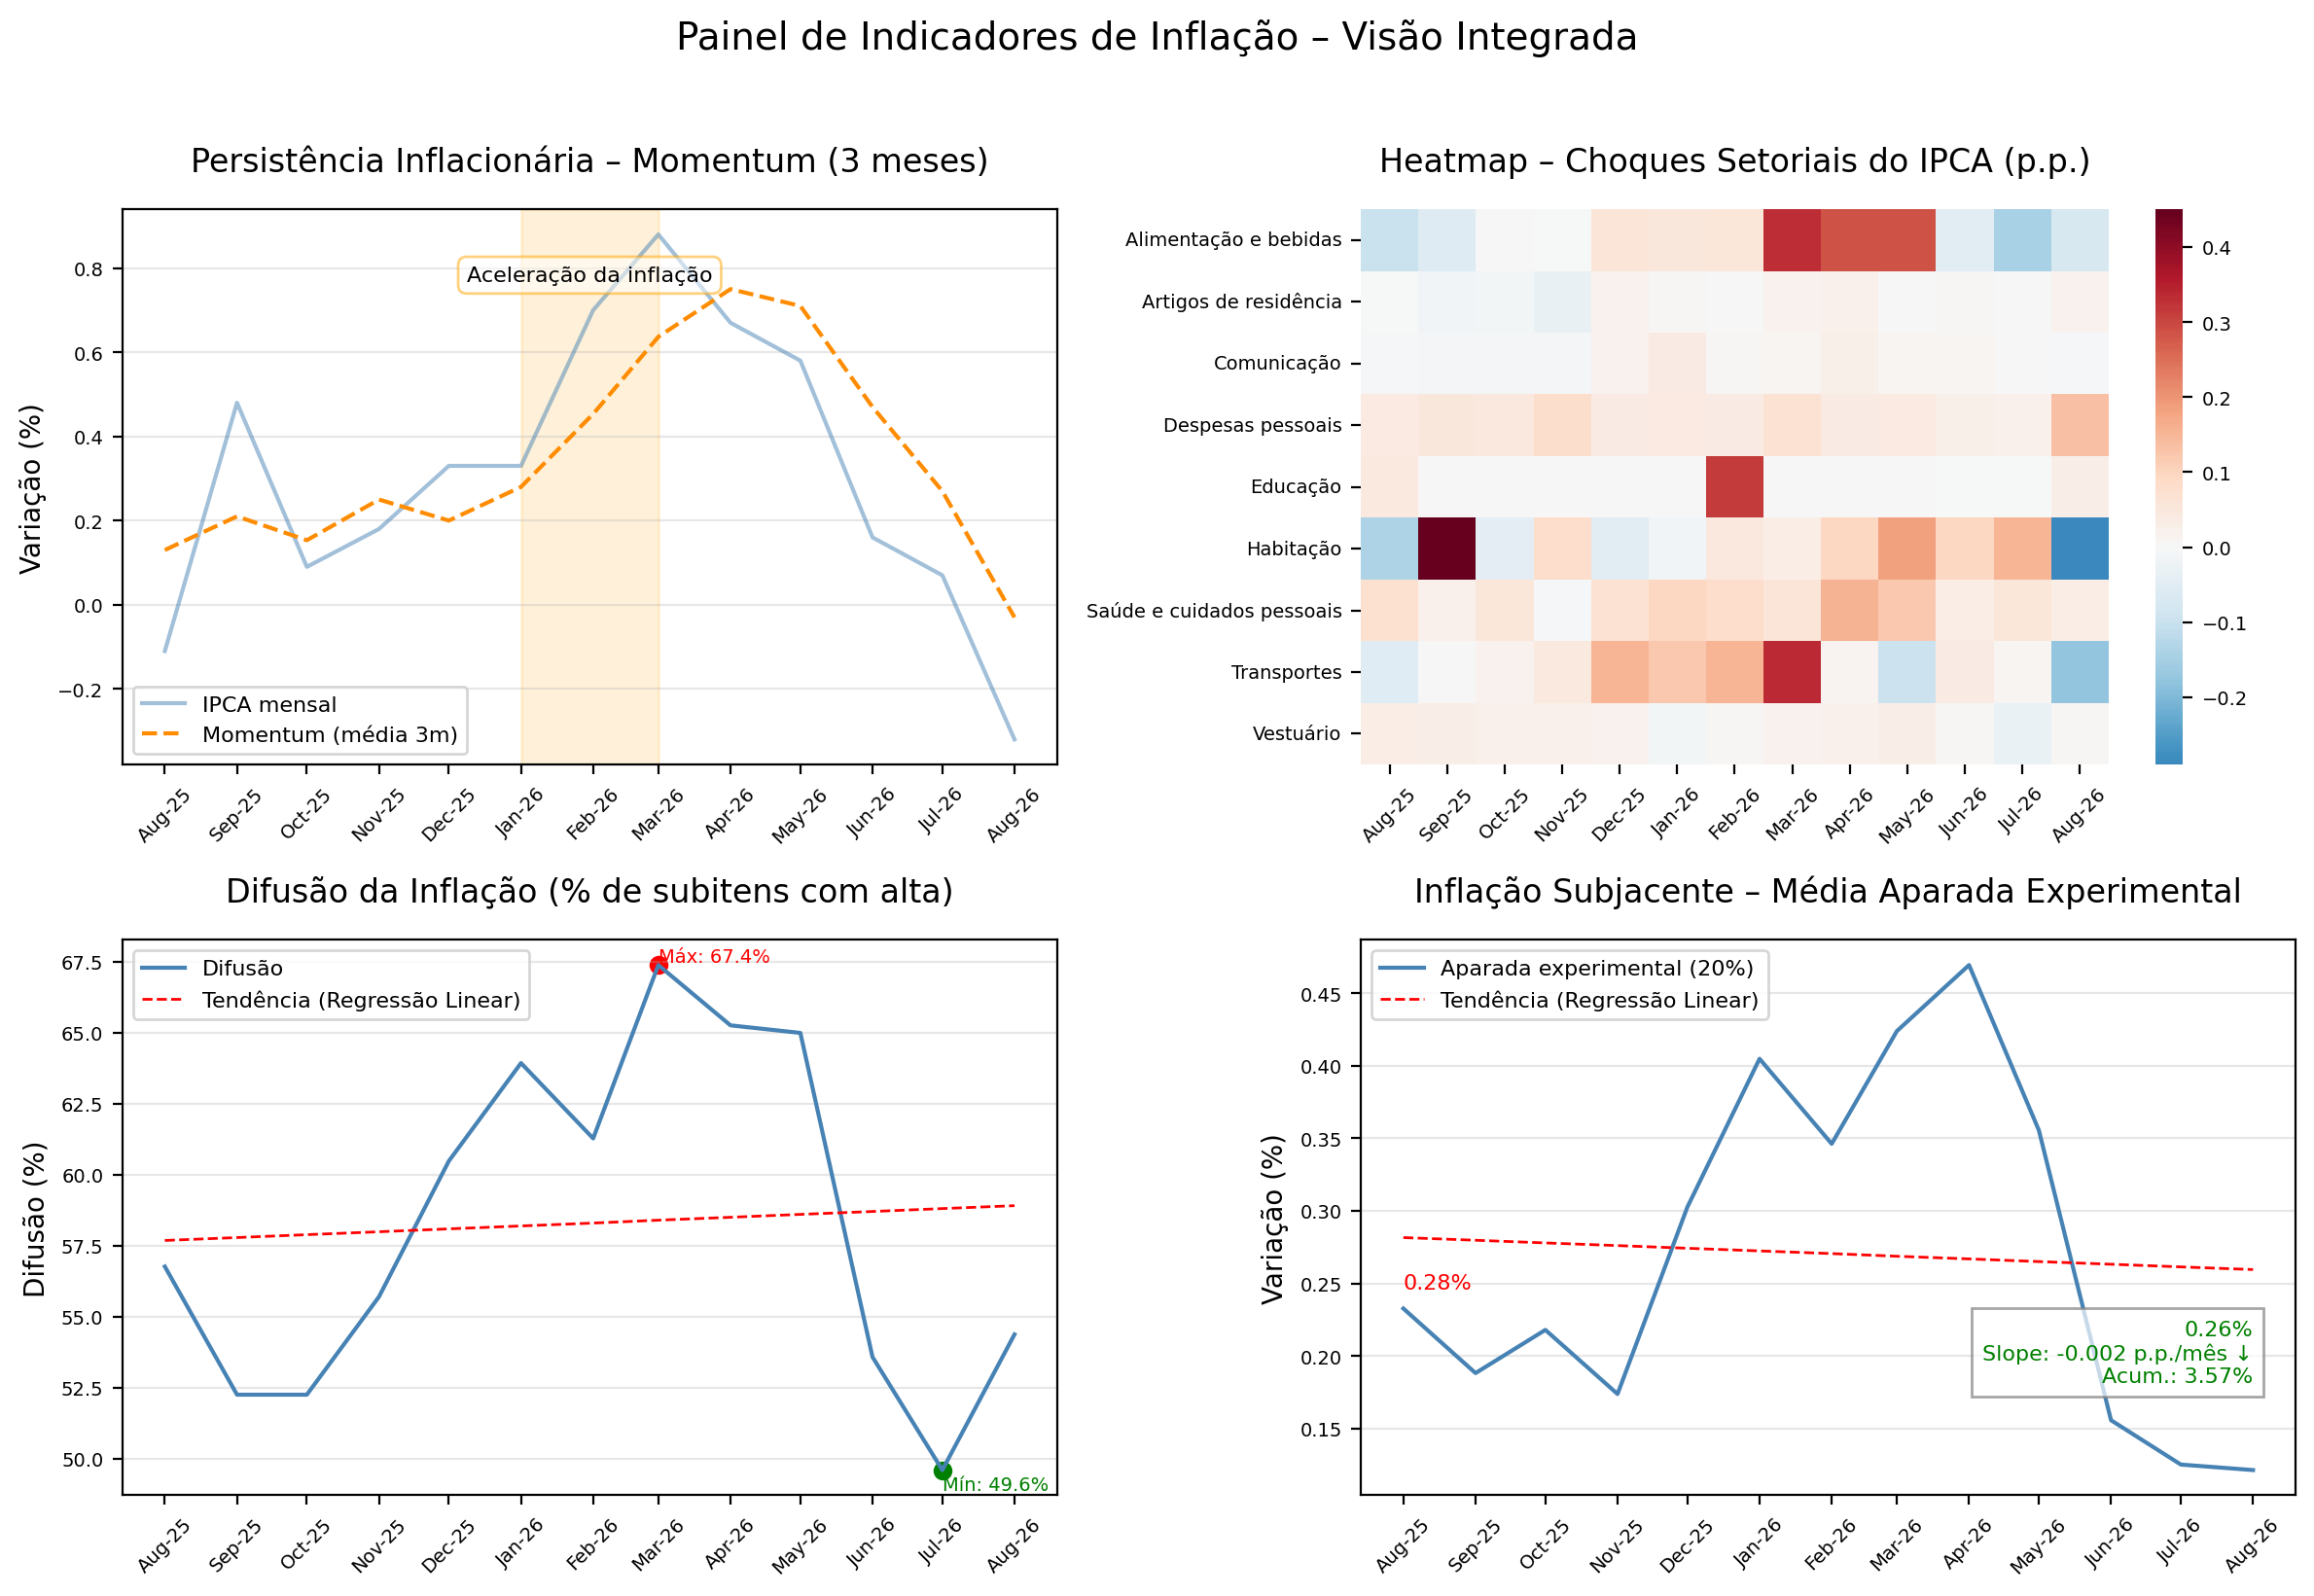

In [12]:
fig, ax = plt.subplots(
    2,
    2,
    figsize=(12, 8),
    dpi=200,
)


# ============================================================
# 0,0 — MOMENTUM / PERSISTÊNCIA
# ============================================================

ax[0, 0].plot(
    df_ipca["date"],
    df_ipca["ipca"],
    label="IPCA mensal",
    alpha=0.5,
    color="steelblue",
)

ax[0, 0].plot(
    df_ipca["date"],
    df_ipca["momentum_3m"],
    "--",
    label="Momentum (média 3m)",
    linewidth=1.5,
    color="darkorange",
)


if (
    inicio is not None
    and fim is not None
):

    ax[0, 0].axvspan(
        inicio,
        fim,
        color="orange",
        alpha=0.15,
    )

    meio = (
        inicio
        + (fim - inicio) / 2
    )

    ax[0, 0].text(
        meio,
        df_ipca["ipca"].max() * 0.89,
        "Aceleração da inflação",
        ha="center",
        va="center",
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="orange",
            alpha=0.5,
        ),
    )


ax[0, 0].set_title(
    "Persistência Inflacionária – Momentum (3 meses)",
    y=1.04,
)

ax[0, 0].set_ylabel(
    "Variação (%)"
)

ax[0, 0].tick_params(
    axis="y",
    labelsize=7,
)

ax[0, 0].tick_params(
    axis="x",
    labelsize=7,
)

ax[0, 0].set_xticks(
    df_ipca["date"]
)

ax[0, 0].set_xticklabels(
    df_ipca["date"]
    .dt.strftime("%b-%y"),
    rotation=45,
)

ax[0, 0].grid(
    axis="y",
    alpha=0.3,
)

ax[0, 0].legend(
    fontsize=8
)


# ============================================================
# 0,1 — HEATMAP
# ============================================================

sns.heatmap(
    df_heat.T,
    cmap="RdBu_r",
    center=0,
    ax=ax[0, 1],
)

cbar = (
    ax[0, 1]
    .collections[0]
    .colorbar
)

cbar.ax.tick_params(
    labelsize=7
)

ax[0, 1].set_title(
    "Heatmap – Choques Setoriais do IPCA (p.p.)",
    y=1.04,
)

ax[0, 1].set_ylabel("")

ax[0, 1].tick_params(
    axis="y",
    labelsize=7,
)

ax[0, 1].set_xlabel("")

ax[0, 1].tick_params(
    axis="x",
    labelsize=7,
    rotation=45,
)


# ============================================================
# 1,0 — DIFUSÃO
# ============================================================

X = np.arange(
    len(df_difusao)
).reshape(-1, 1)

y = (
    df_difusao["difusao"]
    .values
)

modelo = (
    LinearRegression()
    .fit(
        X,
        y,
    )
)

tendencia = (
    modelo.predict(X)
)

slope_difusao = (
    modelo.coef_[0]
)

max_val = (
    df_difusao["difusao"]
    .max()
)

min_val = (
    df_difusao["difusao"]
    .min()
)

max_date = (
    df_difusao.loc[
        df_difusao[
            "difusao"
        ].idxmax(),
        "date",
    ]
)

min_date = (
    df_difusao.loc[
        df_difusao[
            "difusao"
        ].idxmin(),
        "date",
    ]
)


ax[1, 0].plot(
    df_difusao["date"],
    df_difusao["difusao"],
    linewidth=1.5,
    color="steelblue",
    label="Difusão",
)

ax[1, 0].plot(
    df_difusao["date"],
    tendencia,
    "--",
    color="red",
    linewidth=1,
    label="Tendência (Regressão Linear)",
)


ax[1, 0].scatter(
    max_date,
    max_val,
    color="red",
)

ax[1, 0].text(
    max_date,
    max_val + 0.1,
    f"Máx: {max_val:.1f}%",
    fontsize=7,
    color="red",
)


ax[1, 0].scatter(
    min_date,
    min_val,
    color="green",
)

ax[1, 0].text(
    min_date,
    min_val - 0.7,
    f"Mín: {min_val:.1f}%",
    fontsize=7,
    color="green",
)


ax[1, 0].set_title(
    "Difusão da Inflação (% de subitens com alta)",
    y=1.04,
)

ax[1, 0].set_ylabel(
    "Difusão (%)"
)

ax[1, 0].tick_params(
    axis="y",
    labelsize=7,
)

ax[1, 0].tick_params(
    axis="x",
    labelsize=7,
)

ax[1, 0].set_xticks(
    df_difusao["date"]
)

ax[1, 0].set_xticklabels(
    df_difusao["date"]
    .dt.strftime("%b-%y"),
    rotation=45,
)

ax[1, 0].grid(
    axis="y",
    alpha=0.3,
)

ax[1, 0].legend(
    fontsize=8
)


# ============================================================
# 1,1 — INFLAÇÃO APARADA EXPERIMENTAL
# ============================================================

X = np.arange(
    len(df_trim)
).reshape(-1, 1)

y = (
    df_trim["nucleo_aparado"]
    .values
)

modelo = (
    LinearRegression()
    .fit(
        X,
        y,
    )
)

tendencia = (
    modelo.predict(X)
)

t_ini = tendencia[0]

t_fim = tendencia[-1]

slope = (
    modelo.coef_[0]
)

acumulado = (
    (
        (
            1
            + df_trim[
                "nucleo_aparado"
            ]
            / 100
        )
        .prod()
        - 1
    )
    * 100
)

cor_slope = (
    "red"
    if slope > 0
    else "green"
)

seta = (
    "↑"
    if slope > 0
    else "↓"
)


ax[1, 1].plot(
    df_trim["date"],
    df_trim["nucleo_aparado"],
    label="Aparada experimental (20%)",
    linewidth=1.5,
    color="steelblue",
)

ax[1, 1].plot(
    df_trim["date"],
    tendencia,
    "--",
    color="red",
    linewidth=1,
    label="Tendência (Regressão Linear)",
)


ax[1, 1].text(
    df_trim["date"].iloc[0],
    t_ini - 0.035,
    f"{t_ini:.2f}%",
    color="red",
    fontsize=8,
)


ax[1, 1].text(
    df_trim["date"].iloc[-1],
    t_fim - 0.08,
    (
        f"{t_fim:.2f}%\n"
        f"Slope: {slope:.3f} p.p./mês {seta}\n"
        f"Acum.: {acumulado:.2f}%"
    ),
    color=cor_slope,
    fontsize=8,
    ha="right",
    va="bottom",
    bbox=dict(
        facecolor="white",
        alpha=0.7,
        edgecolor="gray",
    ),
)


ax[1, 1].set_title(
    "Inflação Subjacente – Média Aparada Experimental",
    y=1.04,
)

ax[1, 1].set_ylabel(
    "Variação (%)"
)

ax[1, 1].tick_params(
    axis="y",
    labelsize=7,
)

ax[1, 1].tick_params(
    axis="x",
    labelsize=7,
)

ax[1, 1].set_xticks(
    df_trim["date"]
)

ax[1, 1].set_xticklabels(
    df_trim["date"]
    .dt.strftime("%b-%y"),
    rotation=45,
)

ax[1, 1].grid(
    axis="y",
    alpha=0.3,
)

ax[1, 1].legend(
    fontsize=8
)


# ============================================================
# TÍTULO GERAL
# ============================================================

fig.suptitle(
    "Painel de Indicadores de Inflação – Visão Integrada",
    fontsize=14,
    y=1.02,
)

plt.tight_layout()
plt.show()

---

# 7. Como ler o painel

## 7.1 Momentum e persistência

O primeiro quadrante combina:

- IPCA mensal;
- média móvel de três meses;
- último ciclo contínuo de altas mensais.

A média móvel é:

$$
M_t^{(3)}
=
\frac{
\pi_t+\pi_{t-1}+\pi_{t-2}
}{3}
$$

O objetivo é observar o comportamento recente para além da
volatilidade de um único mês.

A faixa laranja destaca visualmente o último episódio de aceleração
identificado na série mensal.

## 7.2 Choques setoriais

O heatmap acrescenta a dimensão de localização.

Para cada grupo:

$$
C_{g,t}
=
\pi_{g,t}
\frac{w_{g,t}}{100}
$$

O painel permite observar:

- grupos pressionando o IPCA;
- grupos produzindo alívio;
- choques pontuais;
- pressões que persistem por vários meses.

## 7.3 Difusão

A difusão mede:

> Qual proporção dos componentes apresentou alta?

$$
D_t
=
\frac{
\sum_i\mathbf{1}(\pi_{i,t}>0)
}{
N_t
}
$$

Além do valor mensal, o gráfico mostra:

- máximo recente;
- mínimo recente;
- tendência linear.

A tendência:

$$
\widehat D_t
=
\beta_0+\beta_1t
$$

possui slope:

$$
\beta_1
$$

que indica a direção do movimento observado na janela.

O slope é descritivo e não representa previsão.

## 7.4 Inflação aparada experimental

O quarto quadrante busca enxergar o centro da distribuição dos
movimentos de preços.

Depois de remover as observações extremas das duas caudas, calculamos
uma média ponderada dos componentes restantes.

O painel mostra:

- trajetória da medida;
- tendência linear;
- slope;
- acumulado composto da janela.

A medida é experimental e não deve ser interpretada como núcleo
oficial do IPCA.

---

# 8. Uma leitura integrada

O objetivo não é interpretar cada gráfico isoladamente.

A combinação é que acrescenta informação.

```text
                      IPCA
                       |
       +---------------+---------------+
       |               |               |
       v               v               v
   velocidade      abrangência       origem
       |               |               |
       v               v               v
   momentum         difusão          heatmap
       |
       +
       |
       v
inflação aparada
       |
       v
pressão além dos extremos
```

## Cenário A

```text
difusão crescente
       +
aparada crescente
       ↓
investigar inflação mais disseminada
e presente no centro da distribuição
```

## Cenário B

```text
IPCA cheio pressionado
       +
aparada relativamente moderada
       ↓
investigar influência de movimentos extremos
```

## Cenário C

```text
perda de momentum
       +
redução da difusão
       ↓
movimento de desinflação potencialmente
mais abrangente
```

Esses cenários são roteiros de investigação.

Não representam classificações automáticas nem previsões.

---

# 9. O que mudou no projeto?

A evolução pode ser vista em três etapas.

## Primeiro

```text
IPCA
  ↓
quanto foi a inflação?
```

## Depois

```text
IPCA
  ↓
grupos
  ↓
subgrupos
  ↓
itens
  ↓
subitens
```

A pergunta passou a ser:

> Onde estão os movimentos?

## Agora

```text
IPCA
 |
 +-- velocidade
 |
 +-- abrangência
 |
 +-- pressão subjacente
 |
 +-- origem setorial
```

A pergunta passa a ser:

> **Como a inflação está se formando?**

---

# 10. Do painel para uma narrativa econômica

O painel fornece um roteiro simples de comunicação.

## 1. Quanto?

Qual foi o IPCA?

## 2. A inflação está ganhando força?

Momentum e ciclo recente ajudam a observar velocidade.

## 3. A alta está disseminada?

A difusão mede quantos componentes estão subindo.

## 4. A pressão permanece sem os extremos?

A inflação aparada experimental observa uma parte mais central da
distribuição.

## 5. De onde vêm as pressões?

O heatmap localiza os grupos responsáveis pelas contribuições.

Assim, o IPCA deixa de ser apenas um resultado mensal e passa a ser
o ponto de partida para uma análise estrutural.

---

# 11. Conclusão

O painel desenvolvido nesta etapa do projeto **Inflation** combina
quatro perspectivas:

```text
Momentum
   ↓
velocidade

Difusão
   ↓
abrangência

Inflação aparada
   ↓
pressão subjacente experimental

Choques setoriais
   ↓
localização
```

Nenhum desses indicadores deve ser interpretado isoladamente.

Juntos, porém, ajudam a responder uma pergunta mais interessante do
que simplesmente:

> Quanto foi o IPCA?

A pergunta começa a se tornar:

> **Qual é a dinâmica por trás do resultado agregado?**

Esse painel representa a transição do projeto de uma etapa de
decomposição e validação para uma etapa de diagnóstico econômico.

---

# 12. Próximos passos

A evolução do projeto segue:

```text
dados
  ↓
estrutura do IPCA
  ↓
decomposição
  ↓
validação
  ↓
dinâmica inflacionária
  ↓
painel integrado            ← etapa atual
  ↓
blocos macroeconômicos
  ↓
política monetária
  ↓
feature engineering
  ↓
modelagem
```

A próxima pergunta será:

> **De onde economicamente está vindo a inflação?**

Essa será a etapa de análise por blocos macroeconômicos.